# Dataset con fondos negativos

El diagnóstico de los modelos finales (`2.2b_diagnostico_test.ipynb`) mostró que detectan como grano entre el 90 % y el 98 % de las impurezas inorgánicas y orgánicas, y que el umbral de confianza no las separa de los granos. Los modelos apenas vieron objetos que no fueran maíz durante el entrenamiento.

Este notebook construye `datos/fondos`: imágenes sin granos, con la etiqueta vacía, que se añaden a `Data_final` para que la red aprenda qué **no** es un grano. No modifica `Data_final`; el entrenamiento combina ambos con `datos/fondos/data.yaml`.

**Fuentes:**
- **Hojas vacías:** 25 fotos de fondo sin granos, tomadas en dos sesiones con distinta iluminación y encuadre; algunas muestran el borde de la mesa. Se leen en su resolución original (de 4032 × 3024 a 5712 × 4284 px). Sus metadatos (ubicación, fecha y dispositivo) se eliminaron; solo se conservan la orientación y el perfil de color.
- **Impurezas inorgánicas y orgánicas:** las 144 imágenes de `Data_corr_v6` que solo las contienen. Se retiraron en el OE1, y ningún modelo las ha visto. Las otras semillas no se usan: la clase se descartó en el OE1 por salir del objetivo.

**Reglas:**
1. **Proporción:** los fondos son el 10 % de cada conjunto (`train` y `valid`), el máximo que recomienda la documentación de Ultralytics para reducir falsos positivos (*Tips for Best Training Results*: 0-10 % de imágenes de fondo).
2. **Sin fuga por sesión de captura:** las impurezas se fotografiaron en las mismas sesiones que los granos. Se agrupan con los granos por lote (mismo criterio que en el OE1) y cada lote va a un solo destino:
   - si comparte lote con granos del test, va a **evaluación**;
   - si comparte lote solo con granos de `valid`, va a `valid`;
   - si comparte lote solo con granos de `train`, es candidato a `train`;
   - si comparte lote con granos de `train` y de `valid`, se descarta.
3. **Conjunto de evaluación:** las impurezas de las sesiones del test y una parte de las hojas forman `datos/fondos/evaluacion`. Ese conjunto no se usa para entrenar ni para decidir, solo para medir los falsos positivos al final. El test de granos no cambia.
4. **Mismo formato que `Data_final`:** letterbox a 1280 px y relleno gris hasta un múltiplo de 32.

In [1]:
import json
import os
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pillow_heif
from IPython.display import display
from PIL import Image, ImageOps

os.environ['YOLO_VERBOSE'] = 'False'   # sin barras de progreso de Ultralytics
import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
SALIDA = RAIZ / 'salida' / '2.2c_fondos'
FRACCION = 0.10                          # fondos sobre el total de cada conjunto
REPARTO_HOJAS = {'train': 0.50, 'valid': 0.15}   # el resto de las hojas va a evaluación
SEMILLA = 42

pillow_heif.register_heif_opener()

def leer_hoja(p):
    """Foto de una hoja vacía en BGR, con la orientación aplicada (HEIC con pillow-heif, JPG con OpenCV)."""
    if p.suffix.lower() == '.heic':
        return cv2.cvtColor(np.asarray(ImageOps.exif_transpose(Image.open(p)).convert('RGB')), cv2.COLOR_RGB2BGR)
    return cv2.imread(str(p))   # imread aplica la orientación EXIF

# Hojas por sesión de captura (fotos/hojas_vacias/sesion_*)
HOJAS = [sorted(p for p in d.iterdir() if p.suffix.lower() in ('.heic', '.jpg')) for d in sorted((E.FOTOS / 'hojas_vacias').glob('sesion_*'))]
tam = Counter(leer_hoja(p).shape[:2][::-1] for v in HOJAS for p in v)
print(f'Hojas vacías: {sum(map(len, HOJAS))} | tamaños (ancho, alto): {dict(tam)}')

Hojas vacías: 25 | tamaños (ancho, alto): {(4032, 3024): 9, (3024, 4032): 9, (4284, 5712): 3, (5712, 4284): 4}


## 1. Impurezas por lote de captura

Las impurezas y los granos de `Data_final` se agrupan juntos por lote (fotos separadas por 5 minutos o menos, o hasta 5 posiciones de contador). El destino de cada lote depende de con qué granos comparte sesión.

In [2]:
impurezas = [r for r in C.leer_dataset(E._DATA_CORR) if r['clases'] and set(r['clases']) <= set(E.IMPUREZAS)]
split_maiz = {p.stem: s for s in ('train', 'valid', 'test') for p in (E.FINAL / s / 'images').glob('*.jpg')}
lote = C.agrupar([r['stem'] for r in impurezas] + list(split_maiz), C.GAP_LOTE)

def destino(splits):
    if 'test' in splits:
        return 'evaluacion'
    if splits == {'valid'}:
        return 'valid'
    if splits == {'train', 'valid'}:
        return 'descartado'
    return 'train'

grupos = defaultdict(lambda: {'imp': [], 'maiz': Counter()})
for r in impurezas:
    grupos[lote[r['stem']]]['imp'].append(r)
for s, sp in split_maiz.items():
    if lote[s] in grupos:
        grupos[lote[s]]['maiz'][sp] += 1
filas = []
for k, g in sorted(grupos.items()):
    tipos = Counter(E.IMPUREZAS[r['clases'][0]] for r in g['imp'])
    filas.append({'lote': k, 'Inorganic': tipos['Inorganic'], 'Organic': tipos['Organic'],
                  'granos en train': g['maiz']['train'], 'granos en valid': g['maiz']['valid'],
                  'granos en test': g['maiz']['test'], 'destino': destino(set(g['maiz']))})
lotes = pd.DataFrame(filas).set_index('lote')
display(lotes)
display(lotes.groupby('destino')[['Inorganic', 'Organic']].sum().assign(total=lambda d: d.sum(axis=1)))

,Inorganic,Organic,granos en train,granos en valid,granos en test,destino
lote,,,,,,
contador_IMG_000,20,15,105,15,0,descartado
contador_IMG_001,6,6,36,0,0,train
tiempo_007,0,10,15,45,0,descartado
tiempo_009,0,11,0,0,43,evaluacion
tiempo_010,18,0,0,0,15,evaluacion
tiempo_011,20,14,120,0,0,train
tiempo_012,4,4,24,0,0,train
tiempo_013,2,2,0,0,12,evaluacion
tiempo_014,2,2,12,0,0,train


,Inorganic,Organic,total
destino,,,
descartado,20,25,45
evaluacion,20,13,33
train,32,26,58
valid,4,4,8


## 2. Selección

Número de fondos por conjunto: el 10 % del total, es decir, `n_granos × 0.10 / 0.90` imágenes.
- **Hojas:** de cada sesión de captura, la mitad a `train`, un 15 % a `valid` y el resto a evaluación.
- **Impurezas de `train`:** completan el cupo, a partes iguales entre inorgánicas y orgánicas, repartidas entre los lotes candidatos.
- **Impurezas de `valid` y de evaluación:** todas las de sus lotes.

In [3]:
rng = np.random.default_rng(SEMILLA)
n_maiz = {s: len(list((E.FINAL / s / 'images').glob('*.jpg'))) for s in ('train', 'valid')}
cupo = {s: round(n * FRACCION / (1 - FRACCION)) for s, n in n_maiz.items()}

seleccion = []   # (conjunto, fuente, tipo, ruta o registro)
for rutas in HOJAS:
    orden = list(rng.permutation(len(rutas)))
    n_tr, n_va = (round(len(rutas) * REPARTO_HOJAS[s]) for s in ('train', 'valid'))
    for i, j in enumerate(orden):
        conj = 'train' if i < n_tr else 'valid' if i < n_tr + n_va else 'evaluacion'
        seleccion.append({'conjunto': conj, 'fuente': 'hoja', 'tipo': 'hoja', 'origen': rutas[j]})

def por_tipo(dest):
    out = defaultdict(lambda: defaultdict(list))
    for k in lotes.index[lotes.destino == dest]:
        for r in grupos[k]['imp']:
            out[E.IMPUREZAS[r['clases'][0]]][k].append(r)
    return out

for dest in ('valid', 'evaluacion'):
    for tipo, por_lote in por_tipo(dest).items():
        for rs in por_lote.values():
            seleccion += [{'conjunto': dest, 'fuente': 'impurezas', 'tipo': tipo, 'origen': r} for r in rs]

n_hojas_train = sum(f['conjunto'] == 'train' for f in seleccion)
resto = cupo['train'] - n_hojas_train
for t, (tipo, por_lote) in enumerate(sorted(por_tipo('train').items())):
    n = resto // 2 + (t < resto % 2)
    colas = [list(rng.permutation(rs)) for _, rs in sorted(por_lote.items())]
    elegidas = []
    while len(elegidas) < n and any(colas):        # una por lote, por turnos
        for cola in colas:
            if cola and len(elegidas) < n:
                elegidas.append(cola.pop())
    seleccion += [{'conjunto': 'train', 'fuente': 'impurezas', 'tipo': tipo, 'origen': r} for r in elegidas]

sel = pd.DataFrame(seleccion)
resumen = sel.groupby(['conjunto', 'tipo'], sort=False).size().unstack(fill_value=0).reindex(['train', 'valid', 'evaluacion'])
resumen['fondos'] = resumen.sum(axis=1)
resumen['imágenes con granos'] = pd.Series(n_maiz)
resumen['fracción de fondos'] = (resumen['fondos'] / (resumen['fondos'] + resumen['imágenes con granos'])).round(3)
display(resumen)
print('Impurezas sin usar: candidatas a train no elegidas',
      sum(len(r) for k in lotes.index[lotes.destino == 'train'] for r in [grupos[k]['imp']]) - (sel.query("conjunto == 'train' and tipo != 'hoja'").shape[0]),
      '| lotes descartados', int(lotes.loc[lotes.destino == 'descartado', ['Inorganic', 'Organic']].values.sum()))

tipo,hoja,Organic,Inorganic,fondos,imágenes con granos,fracción de fondos
conjunto,,,,,,
train,12,13,13,38,345.0,0.099
valid,3,4,4,11,98.0,0.101
evaluacion,10,13,20,43,NaN,NaN


Impurezas sin usar: candidatas a train no elegidas 32 | lotes descartados 45


## 3. Generación

Cada imagen se lleva a 1280 px con el letterbox de `Data_final` y se guarda con una etiqueta vacía. En evaluación, las cajas de las impurezas se guardan aparte (`evaluacion/impurezas/`, con sus clases originales 5 y 6) para medir cuántas se detectan como grano.

In [4]:
shutil.rmtree(E.FONDOS, ignore_errors=True)
for conj in ('train', 'valid'):
    (E.FONDOS / conj / 'images').mkdir(parents=True); (E.FONDOS / conj / 'labels').mkdir(parents=True)
(E.FONDOS / 'evaluacion' / 'images').mkdir(parents=True); (E.FONDOS / 'evaluacion' / 'impurezas').mkdir(parents=True)

nombres = []
for f in seleccion:
    if f['tipo'] == 'hoja':
        p = f['origen']
        nombre = f'hoja_{p.stem.lower()}'
        img, cajas = leer_hoja(p), np.zeros((0, 4))
    else:
        r = f['origen']
        nombre = f"imp_{f['tipo'].lower()}_{r['stem']}"
        img, cajas, clases = cv2.imread(str(r['img'])), r['xyxy'], r['clases']
    out, esc, (dx, dy) = E.letterbox(img)
    cv2.imwrite(str(E.FONDOS / f['conjunto'] / 'images' / f'{nombre}.jpg'), out, [cv2.IMWRITE_JPEG_QUALITY, 95])
    if f['conjunto'] == 'evaluacion':
        H, W = out.shape[:2]
        b = cajas * esc + [dx, dy, dx, dy]
        filas = [f'{c} {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}'
                 for c, (x1, y1, x2, y2) in zip(clases, b)] if f['tipo'] != 'hoja' else []
        (E.FONDOS / 'evaluacion' / 'impurezas' / f'{nombre}.txt').write_text('\n'.join(filas) + ('\n' if filas else ''))
    else:
        (E.FONDOS / f['conjunto'] / 'labels' / f'{nombre}.txt').write_text('')
    nombres.append(nombre)

# Data_final + fondos (rutas relativas a esta carpeta; valen en local y en la nube)
(E.FONDOS / 'data.yaml').write_text('''# Data_final + fondos negativos (hojas vacías e impurezas, etiqueta vacía)
train: [../Data_final/train/images, train/images]
val: [../Data_final/valid/images, valid/images]
test: ../Data_final/test/images
nc: 2
names: ["Healthy", "Defect"]
''')
json.dump({f['conjunto'] + '/' + n: {'tipo': f['tipo'], 'fuente': f['fuente'],
                                     'origen': f['origen'].name if f['tipo'] == 'hoja' else f['origen']['stem'],
                                     'lote': None if f['tipo'] == 'hoja' else lote[f['origen']['stem']]}
           for f, n in zip(seleccion, nombres)},
          open(E.FONDOS / 'fondos.json', 'w'), indent=1, ensure_ascii=False)
print(f'{len(nombres)} imágenes en {E.FONDOS}')

92 imágenes en /home/ismael/Documents/Tesis/maiz-yolo11/datos/fondos


## 4. Verificación

- Número de imágenes por conjunto, etiquetas vacías y tamaño de las imágenes (lado mayor 1280, múltiplos de 32).
- Lectura con el cargador de Ultralytics: los fondos deben aparecer como imágenes sin cajas (*backgrounds*).
- Ningún nombre repetido entre conjuntos, y ninguna impureza de evaluación en un lote de `train` o `valid`.

In [5]:
from ultralytics.data.utils import check_det_dataset
from ultralytics.data.dataset import YOLODataset

ver = []
for conj in ('train', 'valid', 'evaluacion'):
    imgs = sorted((E.FONDOS / conj / 'images').glob('*.jpg'))
    tam = [cv2.imread(str(p)).shape[:2] for p in imgs]
    vacias = [(E.FONDOS / conj / 'labels' / f'{p.stem}.txt').read_text() == '' for p in imgs] if conj != 'evaluacion' else [None]
    ver.append({'conjunto': conj, 'imágenes': len(imgs), 'etiquetas vacías': all(vacias) if conj != 'evaluacion' else '—',
                'lado mayor 1280': all(max(t) == E.IMGSZ for t in tam), 'múltiplos de 32': all(h % 32 == 0 and w % 32 == 0 for h, w in tam)})
display(pd.DataFrame(ver).set_index('conjunto'))

data = check_det_dataset(str(E.FONDOS / 'data.yaml'))
for conj in ('train', 'val'):
    ds = YOLODataset(img_path=data[conj], data=data, augment=False, imgsz=E.IMGSZ)
    n_vacias = sum(len(l['cls']) == 0 for l in ds.labels)
    print(f'Ultralytics, {conj}: {len(ds.labels)} imágenes, {n_vacias} sin cajas ({n_vacias / len(ds.labels):.1%})')

stems = [p.stem for c in ('train', 'valid', 'evaluacion') for p in (E.FONDOS / c / 'images').glob('*.jpg')]
assert len(stems) == len(set(stems)), 'nombres repetidos'
lotes_eval = {lote[f['origen']['stem']] for f in seleccion if f['conjunto'] == 'evaluacion' and f['tipo'] != 'hoja'}
lotes_ent = {lote[f['origen']['stem']] for f in seleccion if f['conjunto'] != 'evaluacion' and f['tipo'] != 'hoja'}
assert not lotes_eval & lotes_ent, 'lotes compartidos entre evaluación y entrenamiento'
print('Sin nombres repetidos ni lotes compartidos entre evaluación y entrenamiento.')

,imágenes,etiquetas vacías,lado mayor 1280,múltiplos de 32
conjunto,,,,
train,38,True,True,True
valid,11,True,True,True
evaluacion,43,—,True,True


Ultralytics, train: 383 imágenes, 38 sin cajas (9.9%)
Ultralytics, val: 109 imágenes, 11 sin cajas (10.1%)
Sin nombres repetidos ni lotes compartidos entre evaluación y entrenamiento.


## 5. Ejemplos

Una imagen de cada tipo en cada conjunto, tal como entra a la red (1280 px).

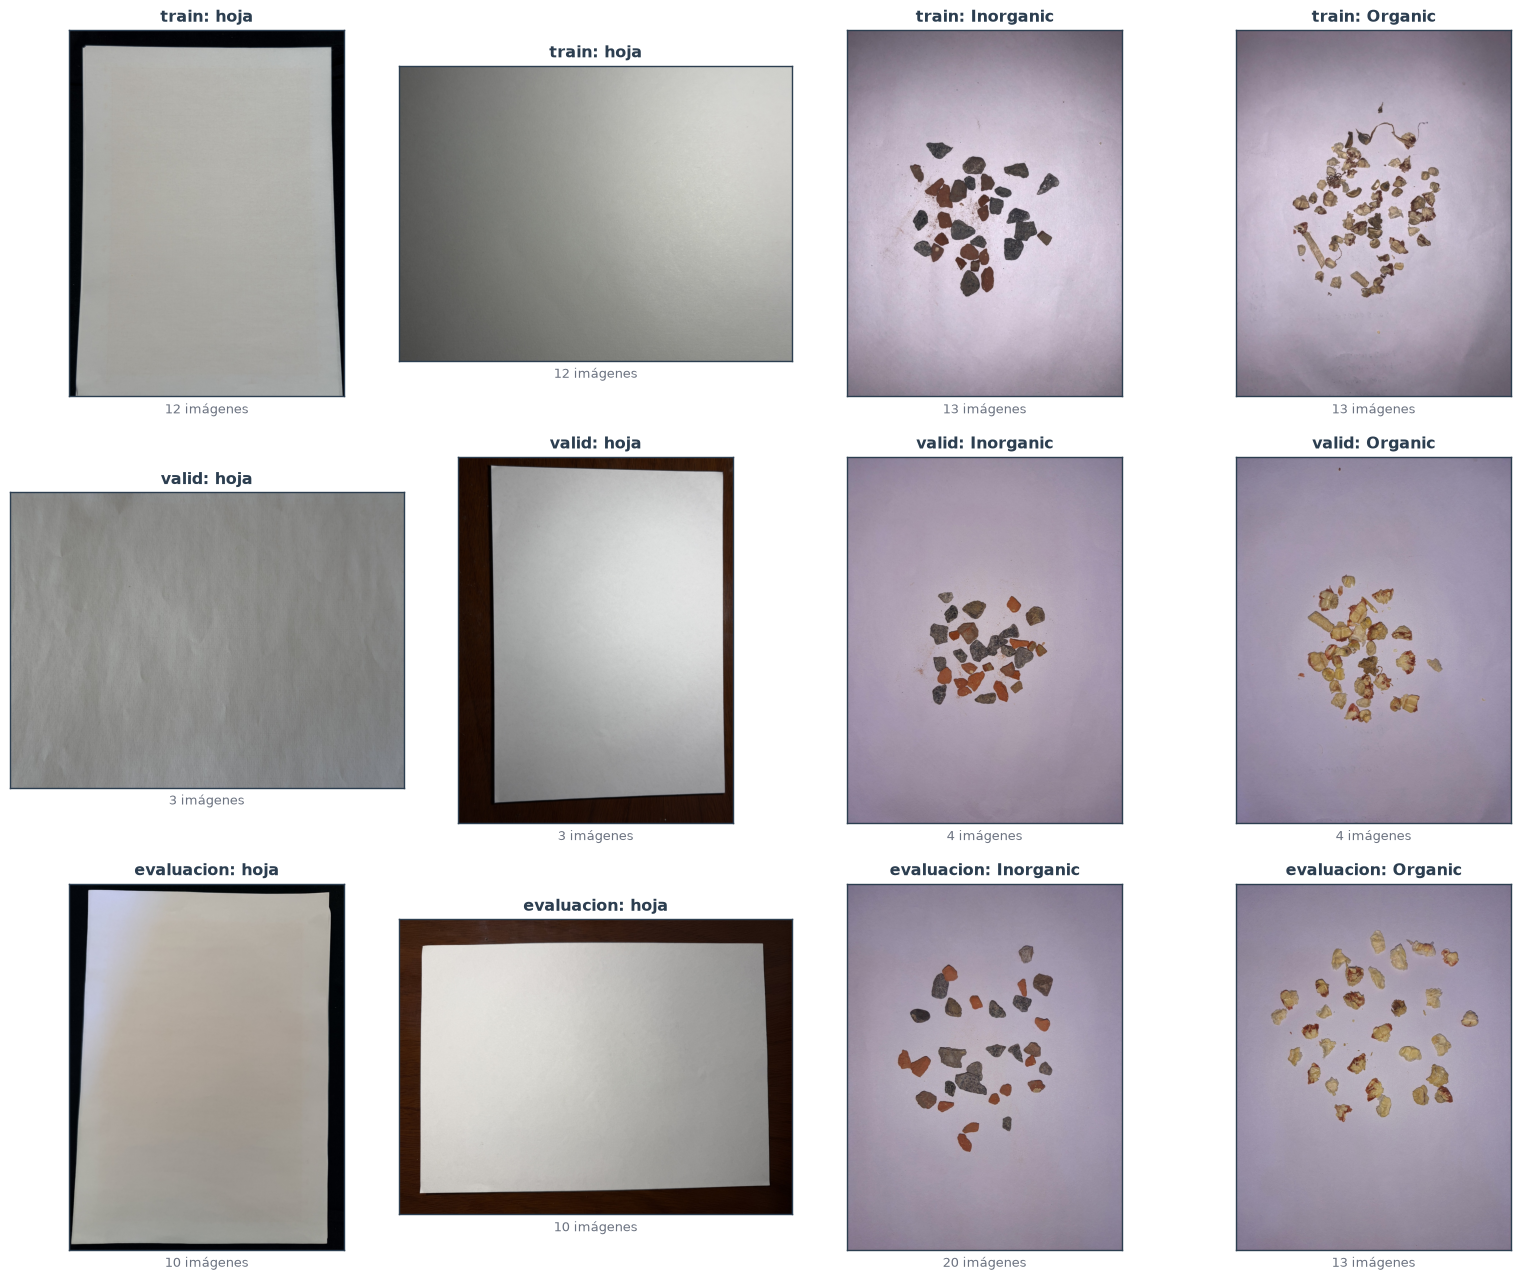

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 13))
for fila, conj in zip(axes, ('train', 'valid', 'evaluacion')):
    hojas = [k for k, f in enumerate(seleccion) if f['conjunto'] == conj and f['tipo'] == 'hoja']
    paneles = [(hojas[0], 'hoja', len(hojas)), (hojas[-1], 'hoja', len(hojas))]
    for tipo in ('Inorganic', 'Organic'):
        i = [k for k, f in enumerate(seleccion) if f['conjunto'] == conj and f['tipo'] == tipo]
        paneles.append((i[0], tipo, len(i)))
    for ax, (k, tipo, n) in zip(fila, paneles):
        img = cv2.cvtColor(cv2.imread(str(E.FONDOS / conj / 'images' / f'{nombres[k]}.jpg')), cv2.COLOR_BGR2RGB)
        E.mostrar(ax, img, f'{conj}: {tipo}', f'{n} imágenes')
C.guardar(SALIDA, 'ejemplos_fondos.png')